# CIVL7024 Assignment 1: Image Processing and 3D Reconstruction

**Group 12**
1. MEI Danyang (3036809634)
2. WENG Dingchen (3036748775)
3. WANG Fengshun (3036708189)
4. HAN Ruida (3036707616)
5. LI Zihao (3036747355)
6. ZHAO Yingchu (3036708579)

In [1]:
from pathlib import Path
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

np.random.seed(42)

def find_file(name):
    for base in (Path('.'), Path('..')):
        direct = base / name
        if direct.exists():
            return direct
        matches = sorted(base.rglob(name))
        if matches:
            return matches[0]
    raise FileNotFoundError(name)

def read_color(name):
    path = find_file(name) if not Path(name).exists() else Path(name)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Cannot read image: {path.name}')
    print(f'{path.name}: {image.shape[1]} x {image.shape[0]}')
    return image

def to_rgb(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def show_images(images, titles, cols=3, cmap=None, scale=(5.0, 3.6)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(scale[0] * cols, scale[1] * rows), squeeze=False)
    for i, (im, title) in enumerate(zip(images, titles)):
        ax = axes.flat[i]
        ax.imshow(im, cmap=cmap if im.ndim == 2 else None)
        ax.set_title(title, fontsize=11)
        ax.axis('off')
    for ax in axes.flat[len(images):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

bridge = read_color('QuebecBridge_EleView.jpg')

QuebecBridge_EleView.jpg: 3888 x 2592


## Part I: Image Processing

### Q1.1 - Q1.3: Downsampling, Bilinear Upsampling, and Evaluation
To shrink the total pixel count to $\frac{1}{4}$ of the original image, we cut both the width and height in half ($\frac{1}{2} \times \frac{1}{2} = \frac{1}{4}$). During **downsampling**, we use area averaging (`cv2.INTER_AREA`) so that groups of pixels are averaged cleanly without jagged **aliasing** artifacts. Next, we enlarge the reduced image back to $3888 \times 2592$ using **bilinear interpolation** (`cv2.INTER_LINEAR`), which estimates each new pixel as a distance-weighted average of its $4$ nearest neighbors.

Original: 3888 x 2592 (10077696 pixels) | Reduced: 1944 x 1296 (2519424 pixels)
MAE: 2.159 | PSNR: 33.607 dB | Grayscale SSIM: 0.96462


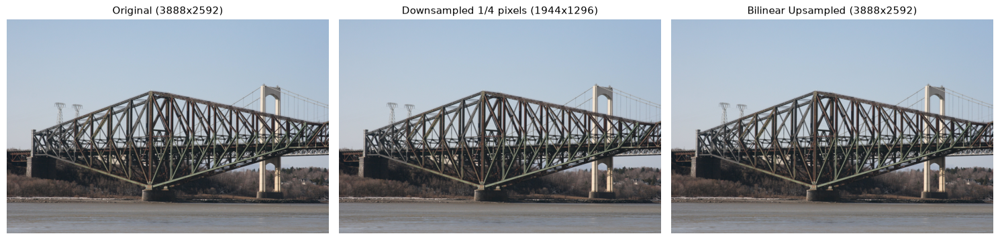

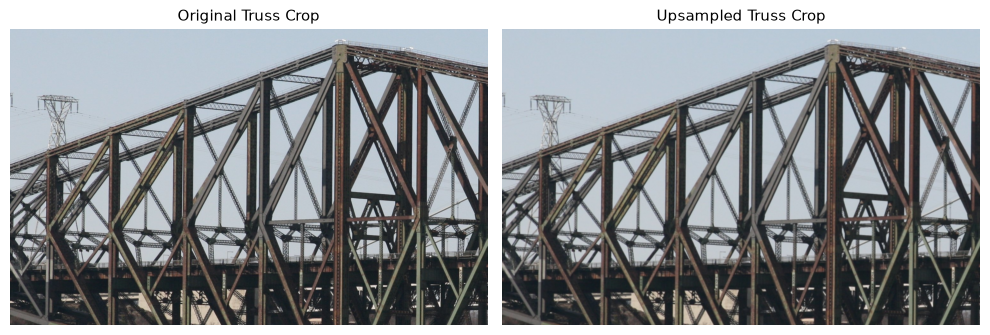

In [2]:
h, w = bridge.shape[:2]
reduced = cv2.resize(bridge, (w // 2, h // 2), interpolation=cv2.INTER_AREA)
restored = cv2.resize(reduced, (w, h), interpolation=cv2.INTER_LINEAR)

mae = np.mean(np.abs(bridge.astype(np.float32) - restored.astype(np.float32)))
psnr = cv2.PSNR(bridge, restored)
ssim = structural_similarity(
    cv2.cvtColor(bridge, cv2.COLOR_BGR2GRAY),
    cv2.cvtColor(restored, cv2.COLOR_BGR2GRAY),
    data_range=255,
)
print(f'Original: {w} x {h} ({w * h} pixels) | Reduced: {reduced.shape[1]} x {reduced.shape[0]} ({reduced.shape[1] * reduced.shape[0]} pixels)')
print(f'MAE: {mae:.3f} | PSNR: {psnr:.3f} dB | Grayscale SSIM: {ssim:.5f}')

show_images(
    [to_rgb(bridge), to_rgb(reduced), to_rgb(restored)],
    ['Original (3888x2592)', 'Downsampled 1/4 pixels (1944x1296)', 'Bilinear Upsampled (3888x2592)'],
)
roi = (slice(820, 1750), slice(700, 2200))
show_images(
    [to_rgb(bridge[roi]), to_rgb(restored[roi])],
    ['Original Truss Crop', 'Upsampled Truss Crop'],
    cols=2,
)

**Comparison and How We Evaluate the Result (Q1.3):**

Because we still have the original $3888 \times 2592$ photo as our ground truth, the most practical way to evaluate the upsampled image is to combine **full-reference quantitative metrics** with **zoomed-in visual inspection** on fine structural parts:

1. **Objective full-reference metrics (`MAE`, `PSNR`, and `SSIM`):**
   - **Mean Absolute Error (`MAE` = $2.159$):** On a $0$ to $255$ brightness scale, each restored pixel is off by only about $2.16$ gray levels on average.
   - **Peak Signal-to-Noise Ratio (`PSNR` = $33.607\text{ dB}$):** Values above $30\text{ dB}$ generally mean the overall pixel-level error is quite small.
   - **Structural Similarity Index (`SSIM` = $0.96462$):** Being very close to $1.0$, this shows that luminance, contrast, and large-scale geometry are well preserved across the whole frame.

2. **Why global numbers are not enough (local visual check):**
   When viewed zoomed out, the upsampled photo looks almost identical to the original because huge parts of the scene are smooth sky and river water where brightness barely changes from pixel to pixel. That drives PSNR and SSIM up. However, once we zoom into the steel truss crop, the difference is obvious: thin diagonal steel bars, rivet joints, and sharp beam-against-sky edges look noticeably softer and slightly blurred.

3. **Why this happens:**
   Throwing away $75\%$ of the pixels during **downsampling** lowers the **sampling rate** and permanently drops **high-frequency spatial details** above the reduced **Nyquist frequency**. When we upsample afterward, **bilinear interpolation** simply blends neighboring pixel values along straight lines. That prevents ugly stair-step pixelation, so transitions look smooth, but it cannot recover real fine texture that was already lost. In short, metrics like PSNR/SSIM measure global fidelity well, while cropped visual inspection is essential for judging edge sharpness in engineering inspection tasks.

### Q1.4 - Q1.5: Spatial Filtering (Box, Gaussian, and Bilateral Filters)

**Differences Between a Box Filter, a Gaussian Filter, and a Bilateral Filter (Q1.4):**

All three are **local neighborhood spatial filters** that compute a weighted average of nearby pixels to reduce noise, but they differ in **how they assign weights** to neighbors:

1. **Box Filter (Mean Filter):**
   Every pixel inside the $K \times K$ window gets the exact same **uniform weight** ($\frac{1}{K^2}$). A pixel sitting at the far corner of the window has just as much influence as the center pixel itself, and the filter pays no attention to edges. As a result, it blurs sharp boundaries aggressively and tends to create unnatural, blocky streaks when the kernel is large.

2. **Gaussian Filter:**
   Instead of treating all neighbors equally, it weights pixels according to their **spatial Euclidean distance** from the center using a bell-shaped **2D Gaussian kernel** controlled by $\sigma_s$. Pixels right next to the center get large weights, while farther pixels fade out smoothly. This gives a much cleaner, more isotropic blur without blocky artifacts. Still, because it only cares about *where* a pixel is and not *what color* it is, it averages dark steel beams and bright sky together right across object borders, softening edges.

3. **Bilateral Filter:**
   The bilateral filter takes one step further by multiplying two Gaussian weights together: a **spatial weight** ($\sigma_{\text{space}}$, based on pixel distance) and a **range / intensity weight** ($\sigma_{\text{color}}$, based on how close two pixels are in brightness or color). If a neighbor has a very similar intensity (for example, two sky pixels), it gets averaged in to smooth out noise. If a neighbor has a very different intensity (such as bright sky right next to a dark brown truss beam), its range weight drops close to zero so the two sides are not mixed. This makes the bilateral filter an **edge-preserving smoothing filter**.

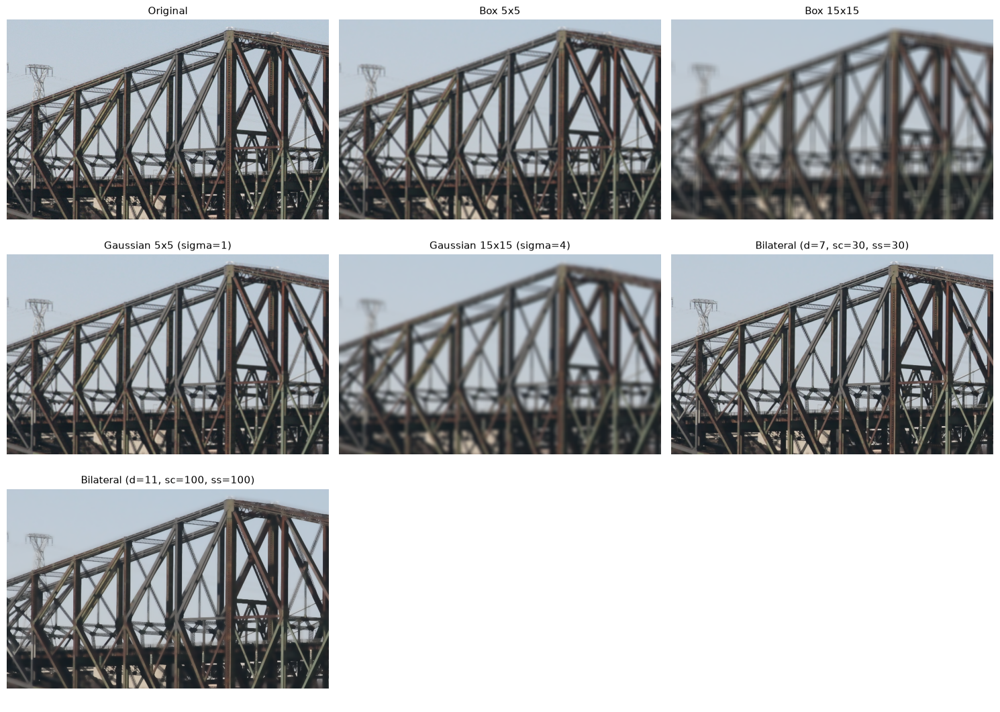

In [3]:
bridge_half = cv2.resize(bridge, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
crop = (slice(410, 875), slice(350, 1100))

filtered_list = [
    bridge_half,
    cv2.blur(bridge_half, (5, 5)),
    cv2.blur(bridge_half, (15, 15)),
    cv2.GaussianBlur(bridge_half, (5, 5), 1.0),
    cv2.GaussianBlur(bridge_half, (15, 15), 4.0),
    cv2.bilateralFilter(bridge_half, 7, 30, 30),
    cv2.bilateralFilter(bridge_half, 11, 100, 100),
]
filter_titles = [
    'Original',
    'Box 5x5',
    'Box 15x15',
    'Gaussian 5x5 (sigma=1)',
    'Gaussian 15x15 (sigma=4)',
    'Bilateral (d=7, sc=30, ss=30)',
    'Bilateral (d=11, sc=100, ss=100)',
]
show_images([to_rgb(im[crop]) for im in filtered_list], filter_titles)

**Discussion of Filtering Results and Parameter Effects (Q1.5):**

Each filter above was run directly on the same reference image so we can compare them side by side on the truss crop:

- **Box filter (`ksize`):** At $5 \times 5$, fine steel members already lose crispness. Jumping to $15 \times 15$ averages over a much wider area, smearing thin diagonal bars into the bright clouds behind them and leaving faint rectangular halos around high-contrast truss openings because corner pixels in the square window carry full weight.
- **Gaussian filter (`ksize` and $\sigma$):** With a small **standard deviation** $\sigma = 1$ ($5 \times 5$), light image grain is smoothed out while the thin steel bracing stays easy to read. Increasing to $15 \times 15$ with $\sigma = 4$ spreads the **spatial kernel** much wider: fine rust texture and thin struts are heavily blurred, though the blur looks noticeably smoother and more natural than the $15 \times 15$ box filter. Even so, every outer steel silhouette becomes fuzzy.
- **Bilateral filter (`d`, `sigmaColor`, and `sigmaSpace`):**
  - At moderate settings (`d=7, sigmaColor=30, sigmaSpace=30`), cloud texture and water ripples become smooth, yet the high-contrast boundaries between the dark steel beams and bright sky stay remarkably sharp.
  - When we raise `sigmaColor` to $100$ and `d` to $11$ (`sigmaSpace=100`), we allow pixels with much bigger brightness differences to blend together. Internally shaded truss faces and medium-contrast details melt into flat, "painterly" or cartoon-like color patches, while only the strongest steel-to-sky borders stay sharp. In general, larger `sigmaSpace` reaches farther spatially, whereas larger `sigmaColor` relaxes edge protection (if `sigmaColor` becomes huge, a bilateral filter eventually turns back into an ordinary Gaussian blur).

### Q1.6 - Q1.7: Frequency-Domain High-Pass and Low-Pass Filtering
We convert the grayscale bridge image into the **frequency domain** using the **2D Fast Fourier Transform (`fft2`)** and shift the zero-frequency (**DC component**) to the center with `fftshift`. Smooth **Gaussian transfer functions** $H_{\text{LP}}(u,v) = \exp(-D^2 / (2 r^2))$ and $H_{\text{HP}}(u,v) = 1 - H_{\text{LP}}(u,v)$ are tested at three **cutoff radii (thresholds)** $r = 25, 80, 200$ pixels. Using a Gaussian roll-off instead of a sharp circular mask prevents wavy **Gibbs ringing artifacts** around strong edges. Because high-pass outputs have positive and negative swings centered around $0$, we add $+128$ when displaying them as 8-bit grayscale images.

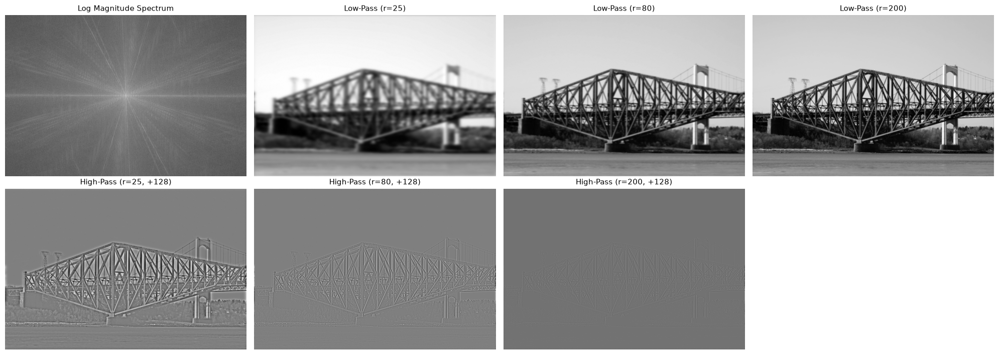

In [4]:
gray = cv2.cvtColor(bridge_half, cv2.COLOR_BGR2GRAY).astype(np.float32)
F = np.fft.fftshift(np.fft.fft2(gray))
yy, xx = np.indices(gray.shape)
fh, fw = gray.shape
dist2 = (xx - fw // 2) ** 2 + (yy - fh // 2) ** 2

cutoffs = [25, 80, 200]
lp_imgs, hp_imgs = [], []
for r in cutoffs:
    lp_mask = np.exp(-dist2 / (2.0 * r ** 2))
    lp = np.real(np.fft.ifft2(np.fft.ifftshift(F * lp_mask)))
    hp = np.real(np.fft.ifft2(np.fft.ifftshift(F * (1.0 - lp_mask))))
    lp_imgs.append(np.clip(lp, 0, 255).astype(np.uint8))
    hp_imgs.append(np.clip(hp + 128, 0, 255).astype(np.uint8))

show_images(
    [np.log1p(np.abs(F)), *lp_imgs, *hp_imgs],
    ['Log Magnitude Spectrum']
    + [f'Low-Pass (r={r})' for r in cutoffs]
    + [f'High-Pass (r={r}, +128)' for r in cutoffs],
    cols=4,
    cmap='gray',
)

**How the Filter Threshold Influences the Results (Q1.6):**

In the **Fourier spectrum**, **low spatial frequencies** near the center represent broad, slowly changing brightness (sky gradients, overall lighting, large silhouettes), whereas **high spatial frequencies** farther out represent rapid intensity jumps (thin truss edges, rivets, foliage texture):

- **Low-pass filter threshold $r$:** Think of $r$ as how wide we open a circular window around the center of the spectrum. When $r = 25$ is small, almost all mid- and high-frequency energy is blocked, so only coarse lighting blobs survive and the bridge looks severely out of focus. Increasing $r$ to $80$ lets medium frequencies pass, bringing the main bridge towers and chords back into recognizable shape. At $r = 200$, most fine frequencies are included as well, so the reconstructed image looks very close to the original sharp photo.
- **High-pass filter threshold $r$:** Because our high-pass mask is $1 - H_{\text{LP}}$, $r$ controls how big a hole we punch out of the center. At a small threshold ($r = 25$), only the slowest background illumination is removed while both medium-width beams and sharp edges are kept, giving bold, high-contrast structural outlines on the gray background. As $r$ increases to $80$ and $200$, more low- and mid-frequency body tones get stripped away too, leaving only the finest $1$-to-$2$ pixel edge transitions, which look thinner and fainter in overall contrast.

**Benefits of Processing Images in the Frequency Domain (Q1.7):**

1. **Much faster computation for large kernels (`Convolution Theorem`):** Convolving an image with a large $K \times K$ filter in the **spatial domain** takes $\mathcal{O}(N K^2)$ operations, which gets slow fast as $K$ grows. In the **frequency domain**, spatial convolution becomes simple element-wise multiplication of arrays after an **FFT** ($\mathcal{O}(N \log N)$), making large-scale smoothing or deconvolution far more efficient.
2. **Easy removal of periodic or directional noise:** Repeating interference patterns (like sensor scanlines, grid moire, or regular background stripes) are spread over every pixel in the raw image, so blurring them spatially ruins sharp details too. In the **magnitude spectrum**, repeating patterns concentrate into a few bright, isolated frequency spikes that we can mask out cleanly with a **band-reject / notch filter** while leaving the rest of the photo intact.
3. **Clear separation of physical scales and orientations:** Frequency-domain filtering lets us directly control which spatial wavelengths we keep or suppress (`low-pass` for illumination normalization/denoising, `high-pass` for edge sharpening, or `band-pass` for specific texture scales). Even looking at the log spectrum itself gives structural insight: the bright tilted lines radiating from the center come directly from the dominant angles of the bridge's steel chords and diagonals.

### Q1.8: Building Our Own Canny Edge Detector
Without calling OpenCV's built-in `cv2.Canny`, we implement the four classic stages of the **Canny edge detection pipeline** from scratch:
1. **Gaussian smoothing** ($5 \times 5$, $\sigma = 1.4$) to quiet down pixel-level sensor noise before taking derivatives;
2. **Intensity gradient calculation** using $3 \times 3$ **Sobel operators** ($G_x, G_y$) to get both **gradient magnitude** $\sqrt{G_x^2 + G_y^2}$ and **gradient direction** $\theta = \operatorname{atan2}(G_y, G_x)$;
3. **Non-maximum suppression (NMS)** using bilinear subpixel sampling (`cv2.remap`) one pixel forward and backward along $(\cos\theta, \sin\theta)$, zeroing out any pixel that is not a strict local peak across the edge ridge;
4. **Double thresholding and hysteresis tracking** (`low_ratio = 0.08`, `high_ratio = 0.20`), where **strong edge** pixels above the high threshold are always kept, and **weak edge** pixels between the two thresholds are kept only if they belong to an $8$-connected component touching at least one strong pixel.

Detected edge pixels: 118597


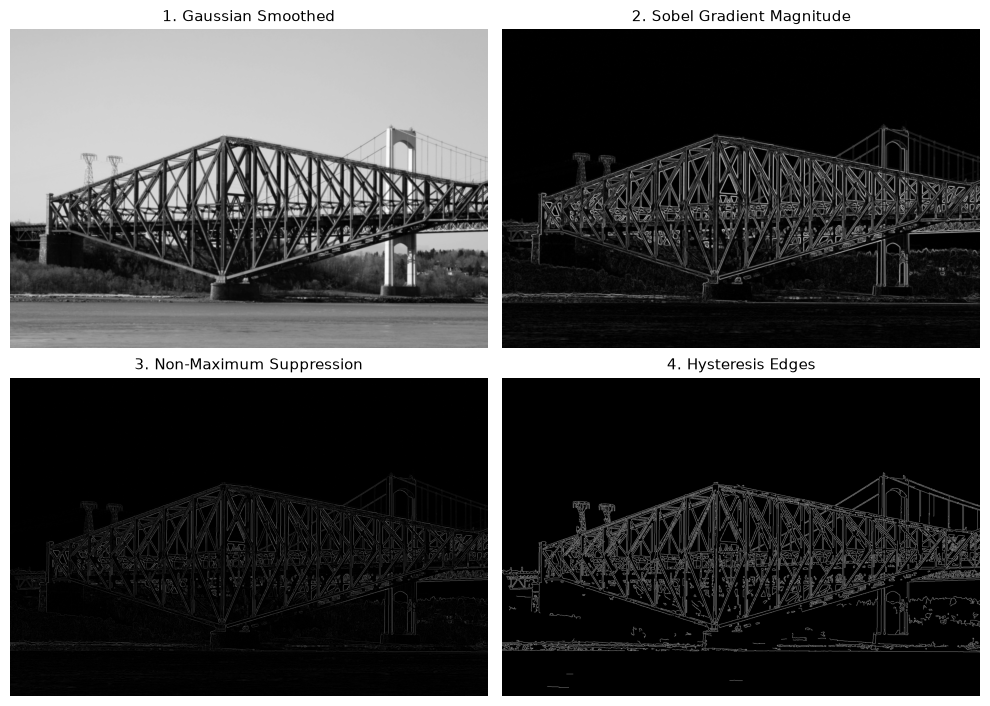

In [5]:
def custom_canny(gray_u8, low_ratio=0.08, high_ratio=0.20, sigma=1.4):
    smooth = cv2.GaussianBlur(gray_u8, (5, 5), sigma).astype(np.float32)
    gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)
    mag = cv2.magnitude(gx, gy)
    angle = np.arctan2(gy, gx)

    ys, xs = np.indices(mag.shape, dtype=np.float32)
    dx = np.cos(angle).astype(np.float32)
    dy = np.sin(angle).astype(np.float32)
    fwd = cv2.remap(mag, xs + dx, ys + dy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    bwd = cv2.remap(mag, xs - dx, ys - dy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    nms = np.where((mag >= fwd) & (mag >= bwd), mag, 0.0).astype(np.float32)

    peak = float(nms.max())
    strong = (nms >= high_ratio * peak).astype(np.uint8)
    weak = (nms >= low_ratio * peak).astype(np.uint8)

    num_labels, labels = cv2.connectedComponents(weak, connectivity=8)
    keep = np.zeros(num_labels, dtype=bool)
    keep[np.unique(labels[strong != 0])] = True
    keep[0] = False
    edges = (keep[labels] * 255).astype(np.uint8)
    return smooth, mag, nms, edges

smooth, mag, nms, edges = custom_canny(gray.astype(np.uint8))
print('Detected edge pixels:', int(np.count_nonzero(edges)))
show_images(
    [smooth, mag, nms, edges],
    ['1. Gaussian Smoothed', '2. Sobel Gradient Magnitude', '3. Non-Maximum Suppression', '4. Hysteresis Edges'],
    cols=2,
    cmap='gray',
)

**Discussion of Our Custom Canny Detector (Q1.8):**

Looking across the four stages shows why each step in Canny matters:
- Raw **Sobel gradient magnitudes** light up all the steel members nicely, but the lines are several pixels thick and blurry.
- **Non-maximum suppression** shaves those thick gradient bands down into crisp, single-pixel centerlines by keeping only the ridge crest along the gradient direction.
- **Hysteresis thresholding** solves the classic single-threshold dilemma: if we used only a high threshold, shaded segments of steel beams would break into dashed lines; if we used only a low threshold, ripples on the water and clouds would flood the output with noise. Connecting weak edges to strong ones keeps continuous bridge members ($118{,}597$ edge pixels) while dropping isolated background clutter.
- *Note on the optional truss connectivity bonus:* Turning this 2D binary edge map into actual structural **node coordinates** and **element connectivity** is non-trivial on an oblique photo like this, because the front and back truss planes overlap in 2D projection and trees/water edges are mixed in. A practical pipeline would need straight line-segment extraction (e.g., **Hough Transform** or **LSD**), vanishing-point grouping to separate the near truss plane, and clustering of line intersections to identify true pin/gusset joints.

---
### Q2.1 - Q2.2: Tung Ping Chau Grayscale Conversion and Harris Corner Detection

**Why We Convert the Images to Grayscale First (Q2.1):**
1. **Feature detectors measure brightness gradients, not color:** Both the **Harris corner detector** and **SIFT** work by computing spatial intensity derivatives ($I_x, I_y$) to find corners and local blobs. Converting 3-channel BGR color into a single **luminance (grayscale)** channel gives one clean scalar intensity field to differentiate, rather than three separate channels whose gradients might slightly disagree.
2. **Speed and memory efficiency:** Dropping from $3$ channels to $1$ cuts the pixel data by two-thirds, making convolution, Gaussian pyramid construction, and descriptor extraction noticeably faster on $21$-megapixel drone photos.
3. **Robustness to slight color/white-balance shifts:** Outdoor drone photos taken from different angles often have slight color-tint changes on water or rocks due to sunlight reflection. Using grayscale luminance keeps keypoint detection focused on physical geometry, while we still hold onto the original RGB images so the final stitched panorama is rendered in full color.

*(Note: We downsample both $5280 \times 3956$ photos by $0.5\times$ to $2640 \times 1978$ so corner detection, matching, and canvas warping run smoothly in memory while keeping plenty of shoreline detail.)*

tung_ping_chau_view1.jpeg: 5280 x 3956


tung_ping_chau_view2.jpeg: 5280 x 3956


Harris corners detected: view1 = 13037, view2 = 43407


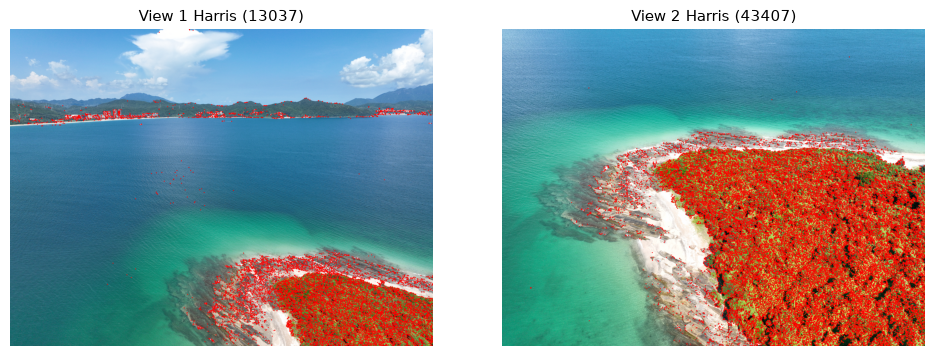

In [6]:
view1_full = read_color('tung_ping_chau_view1.jpeg')
view2_full = read_color('tung_ping_chau_view2.jpeg')

scale = 0.5
v1 = cv2.resize(view1_full, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
v2 = cv2.resize(view2_full, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
g1 = cv2.cvtColor(v1, cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(v2, cv2.COLOR_BGR2GRAY)

def detect_harris(color_im, gray_im):
    resp = cv2.cornerHarris(np.float32(gray_im) / 255.0, blockSize=2, ksize=3, k=0.04)
    mask = (resp > 0.01 * resp.max()).astype(np.uint8)
    count, _, _, centroids = cv2.connectedComponentsWithStats(mask)
    vis = color_im.copy()
    for x, y in centroids[1:]:
        cv2.circle(vis, (round(x), round(y)), 3, (0, 0, 255), -1)
    return vis, count - 1

h1, n1 = detect_harris(v1, g1)
h2, n2 = detect_harris(v2, g2)
print(f'Harris corners detected: view1 = {n1}, view2 = {n2}')
show_images([to_rgb(h1), to_rgb(h2)], [f'View 1 Harris ({n1})', f'View 2 Harris ({n2})'], cols=2)

**Harris Corner Observation (Q2.2):** The **Harris detector** looks at the $2 \times 2$ **structure tensor** of image gradients ($I_x^2, I_y^2, I_x I_y$) in a local window and flags locations where both eigenvalues are large, meaning intensity changes sharply in *all* directions. That is why open sea and sky have almost zero red dots, whereas jagged sedimentary rock ledges and dense island tree canopies pack tens of thousands of corners ($13{,}037$ in View 1 and $43{,}407$ in View 2, which covers a much larger land area).

---
### Q2.3 - Q2.5: SIFT Keypoints, BFMatcher, and Homography with RANSAC

While Harris finds corner locations, raw corners are sensitive to scale/zoom changes and do not carry a distinctive descriptor for matching two noticeably rotated/zoomed drone views. We therefore extract up to $5{,}000$ **SIFT (Scale-Invariant Feature Transform)** keypoints and $128$-dimensional gradient **descriptors** per image (`SIFT_create(nfeatures=5000)`), match them with `BFMatcher(cv2.NORM_L2)`, and apply **Lowe's ratio test** ($d_1 < 0.72\,d_2$) to keep only unambiguous matches where the best match is clearly closer than the second-best match.

**How RANSAC Works Here to Estimate the Homography Matrix (Q2.5):**
Even after Lowe's ratio test narrows things down to $181$ good-looking matches, some wrong matches (**outliers**) inevitably slip in because ocean waves, foam, and bushes have repetitive textures that look alike in feature space. A **planar homography matrix** $H$ ($3 \times 3$, with $8$ **degrees of freedom**) maps points from View 2 to View 1. If we estimated $H$ directly using ordinary least squares on all $181$ pairs, even a few wild outliers far across the image would pull the entire transformation crooked.

**RANSAC (Random Sample Consensus)** protects the fit through repeated hypothesis-and-voting:
1. **Minimal random sampling:** In each iteration, RANSAC randomly picks just **$4$ matched point pairs** (the minimum number needed to uniquely solve the $8$ degrees of freedom of a candidate homography $\hat{H}$).
2. **Consensus voting via reprojection error:** It projects all $181$ matched points from View 2 into View 1 using $\hat{H}$ and measures the Euclidean distance (**reprojection error**) between each projected point and its actual matched point in View 1. Every pair whose error is under the threshold ($4.0\text{ pixels}$) casts a vote as an **inlier** supporting $\hat{H}$.
3. **Selecting and refining the best model:** If any of the $4$ sampled points was an outlier, $\hat{H}$ will be wrong and almost nobody else will vote for it. When all $4$ sampled points happen to be true shoreline matches, nearly all genuine matches agree at once! After running many random trials, RANSAC picks the candidate with the largest **inlier consensus set** ($162$ out of $181$ matches, or $89.5\%$), throws away the $19$ outliers completely, and re-computes the final polished **homography matrix** $H$ using all $162$ clean inliers.

Number of SIFT keypoints: view1 = 5000, view2 = 5000
Matches after ratio test: 181
Homography Matrix H (view2 -> view1):
 [[ 4.69573784e-01 -3.08497673e-01  1.06441273e+03]
 [-6.99290100e-02  6.82590630e-01  6.58267288e+02]
 [-1.71200214e-04 -1.00429941e-04  1.00000000e+00]]
RANSAC inliers: 162 / 181 (89.5%)
Median inlier reprojection error: 1.120 px


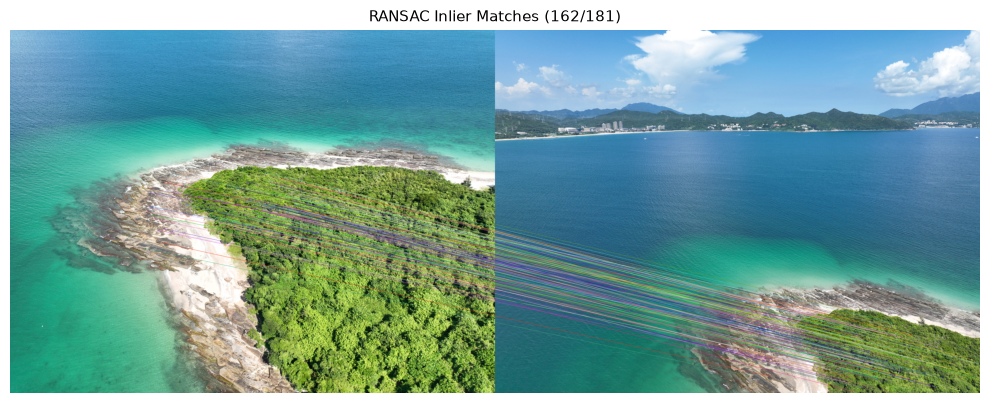

In [7]:
sift = cv2.SIFT_create(nfeatures=5000)
kp1, desc1 = sift.detectAndCompute(g1, None)
kp2, desc2 = sift.detectAndCompute(g2, None)
print(f'Number of SIFT keypoints: view1 = {len(kp1)}, view2 = {len(kp2)}')

bf = cv2.BFMatcher(cv2.NORM_L2)
knn_matches = bf.knnMatch(desc2, desc1, k=2)
good_matches = [m for m, n in knn_matches if m.distance < 0.72 * n.distance]
print('Matches after ratio test:', len(good_matches))

src_pts = np.float32([kp2[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp1[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
H, inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 4.0)
inlier_count = int(inliers.sum())

print('Homography Matrix H (view2 -> view1):\n', H)
print(f'RANSAC inliers: {inlier_count} / {len(good_matches)} ({inlier_count / len(good_matches):.1%})')

proj = cv2.perspectiveTransform(src_pts, H).reshape(-1, 2)
reproj_err = np.linalg.norm(proj - dst_pts.reshape(-1, 2), axis=1)
print(f'Median inlier reprojection error: {float(np.median(reproj_err[inliers.ravel() != 0])):.3f} px')

match_img = cv2.drawMatches(
    v2, kp2, v1, kp1, good_matches, None,
    matchesMask=inliers.ravel().tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
match_img = cv2.resize(match_img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
show_images([to_rgb(match_img)], [f'RANSAC Inlier Matches ({inlier_count}/{len(good_matches)})'], cols=1, scale=(10.0, 5.0))

### Q2.6 - Q2.7: Perspective Warping and Panorama Stitching
If we passed View 2 directly into `cv2.warpPerspective` using only View 1's image dimensions, any warped pixels landing at negative coordinates or outside View 1's borders would get clipped off. Instead, we first pass View 2's four corners through `cv2.perspectiveTransform` to find the bounding box of both images combined, shift everything onto positive canvas coordinates with a $3 \times 3$ **translation matrix** $T$, warp View 2 via $T H$, and blend the overlapping region using **distance-transform feathering** so brightness differences between the two shots transition smoothly rather than leaving a harsh cut line.

Stitched canvas size: 4846 x 5216 | Overlap pixels: 2232031


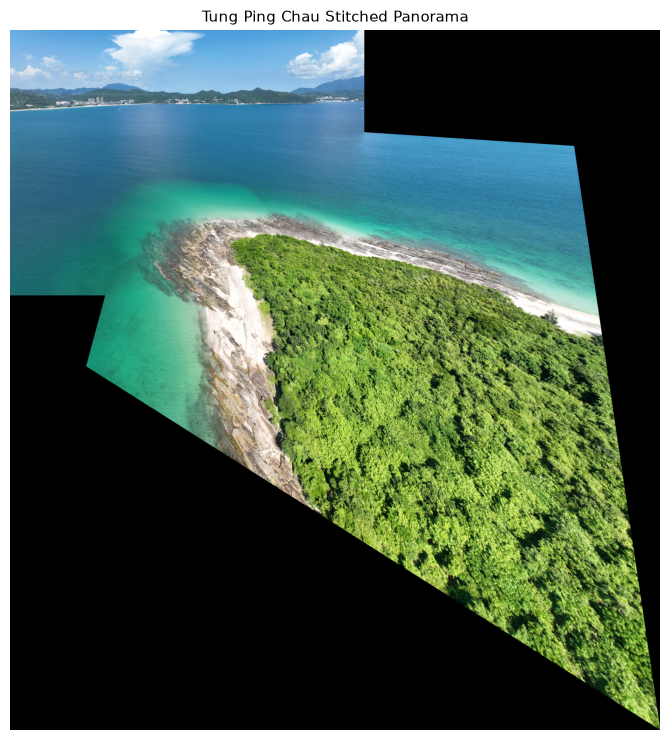

In [8]:
def stitch_pair(base, moving, H_mat):
    hb, wb = base.shape[:2]
    hm, wm = moving.shape[:2]
    c1 = np.float32([[0, 0], [wb - 1, 0], [wb - 1, hb - 1], [0, hb - 1]]).reshape(-1, 1, 2)
    c2 = np.float32([[0, 0], [wm - 1, 0], [wm - 1, hm - 1], [0, hm - 1]]).reshape(-1, 1, 2)
    warped_c2 = cv2.perspectiveTransform(c2, H_mat)
    all_pts = np.vstack((c1, warped_c2)).reshape(-1, 2)

    xy_min = np.floor(all_pts.min(axis=0)).astype(int)
    xy_max = np.ceil(all_pts.max(axis=0)).astype(int)
    width, height = (xy_max - xy_min + 1).tolist()

    T = np.array([[1.0, 0.0, -xy_min[0]], [0.0, 1.0, -xy_min[1]], [0.0, 0.0, 1.0]])
    canvas_wh = (int(width), int(height))
    warped = cv2.warpPerspective(moving, T @ H_mat, canvas_wh)
    mask2 = cv2.warpPerspective(np.ones((hm, wm), np.uint8), T @ H_mat, canvas_wh, flags=cv2.INTER_NEAREST)

    canvas1 = np.zeros_like(warped)
    mask1 = np.zeros((height, width), np.uint8)
    x0, y0 = (-xy_min).tolist()
    canvas1[y0:y0 + hb, x0:x0 + wb] = base
    mask1[y0:y0 + hb, x0:x0 + wb] = 1

    d1 = cv2.distanceTransform(mask1, cv2.DIST_L2, 3)
    d2 = cv2.distanceTransform(mask2, cv2.DIST_L2, 3)
    w_map = d2 / (d1 + d2 + 1e-6)
    stitched = (
        canvas1.astype(np.float32) * (1.0 - w_map[..., None])
        + warped.astype(np.float32) * w_map[..., None]
    ).clip(0, 255).astype(np.uint8)
    return stitched, mask1, mask2, canvas_wh

panorama, m1, m2, pano_size = stitch_pair(v1, v2, H)
print(f'Stitched canvas size: {pano_size[0]} x {pano_size[1]} | Overlap pixels: {int(np.count_nonzero(m1 & m2))}')
show_images([to_rgb(panorama)], ['Tung Ping Chau Stitched Panorama'], cols=1, scale=(9.0, 7.5))

**Discussion of the Tung Ping Chau Panorama (Q2.6 - Q2.7):**
- **Alignment accuracy:** All $162$ RANSAC inliers sit right along the shared rocky reef and island edge, achieving a tight $1.12\text{ px}$ median **reprojection error**. As a result, the wave-cut rock ledges and turquoise shallow water line up very cleanly across the $2.23$-million-pixel overlap region.
- **Why slight seams and black borders appear:** Looking closely at the upper boundary where the distant mainland coast meets the water, or at tall bushes on the island, a mild perspective transition is still visible. That happens because the drone translated in 3D space between the two photos rather than rotating purely around its camera center. A single $3 \times 3$ **planar homography** is mathematically exact only when the scene is flat or camera motion is pure rotation; when there is real depth variation (**parallax**), locking $H$ onto the near reef plane inevitably leaves small shifts at other depths. Meanwhile, the black corners simply correspond to areas of the rectangular $4846 \times 5216$ bounding canvas that neither camera pointed at.

---
## Part II: 3D Reconstruction from Self-Collected Images

### 1. Multi-View Capture and COLMAP Photogrammetry Reconstruction
For Part II, we placed a small plush puppy keychain on a textured wooden desk and captured **52 overlapping smartphone photos** ($3024 \times 4032$) walking in two $360^\circ$ rings around it (a lower oblique ring and a higher top-down ring) while keeping the plush puppy completely stationary in the center.

We then ran the complete **photogrammetry** pipeline in **COLMAP**:
1. **Feature extraction & matching:** Extracted **SIFT** keypoints assuming a shared single-camera `SIMPLE_RADIAL` **intrinsic model** across all $52$ frames and performed **exhaustive matching** with guided geometric verification.
2. **Sparse Structure-from-Motion (`SfM`):** Incremental **triangulation** and global **Bundle Adjustment** successfully registered **all $52$ out of $52$ camera poses ($100\%$)** (`sparse/0`), calibrating focal length $f = 5864.88\text{ px}$ and radial distortion $k = 0.0994$, and reconstructing **$9{,}542$ sparse 3D points** across $29{,}220$ image observations with a mean **reprojection error** of **$1.129\text{ px}$**.
3. **Dense Multi-View Stereo (`MVS`) & Surface Reconstruction:** After **image undistortion**, CUDA **PatchMatch Stereo** and geometric **stereo fusion** produced $706{,}936$ outlier-filtered dense 3D points, followed by **Screened Poisson Surface Reconstruction** (`Part2_3D_Reconstruction.ply`, **$589{,}901$ colored 3D vertices** and **$1{,}172{,}457$ triangles**), giving a complete $360^\circ$ surface model that opens directly in both point-cloud and mesh viewers.

Below we show $6$ sample photos from our $52$-image set alongside the $52$ reconstructed camera poses and multi-view 3D renders of `Part2_3D_Reconstruction.ply`.

Loaded 52 self-collected images (reconstruction_images/)


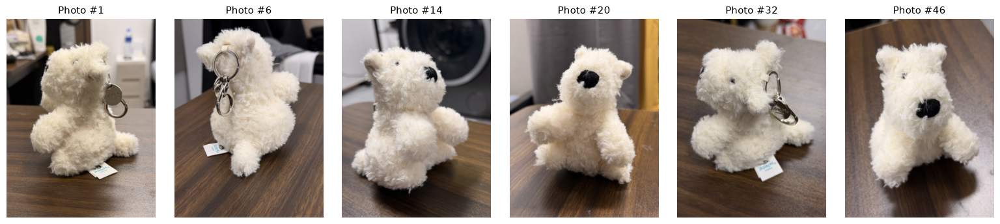

Registered cameras: 52/52 | PLY model: 589,901 vertices, 1,172,457 triangles


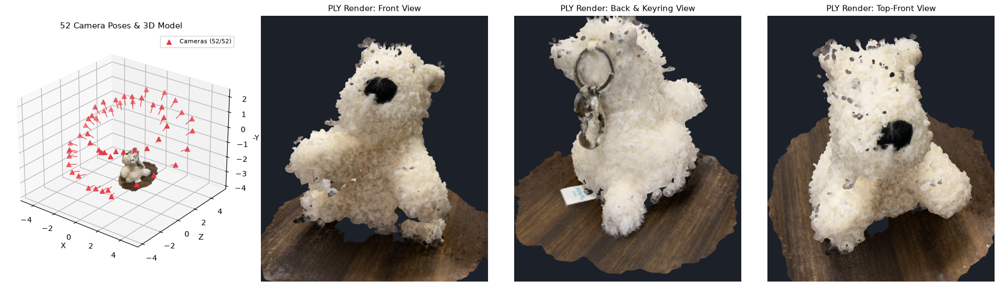

In [9]:
def natural_sort_key(p):
    return [int(tok) if tok.isdigit() else tok.lower() for tok in re.split(r'(\d+)', p.name)]

recon_folder = find_file('reconstruction_images')
own_photos = sorted(recon_folder.glob('*.jpg'), key=natural_sort_key)
print(f'Loaded {len(own_photos)} self-collected images ({own_photos[0].parent.name}/)')

sample_ids = [0, 5, 13, 19, 31, 45]
thumbs, thumb_titles = [], []
for idx in sample_ids:
    im = cv2.imdecode(np.fromfile(str(own_photos[idx]), dtype=np.uint8), cv2.IMREAD_COLOR)
    thumbs.append(to_rgb(cv2.resize(im, (450, 600), interpolation=cv2.INTER_AREA)))
    thumb_titles.append(f'Photo #{idx + 1}')

show_images(thumbs, thumb_titles, cols=6, scale=(2.6, 3.4))

# Read COLMAP camera poses and submitted 3D PLY model
img_file = find_file('images.txt')
ply_file = find_file('Part2_3D_Reconstruction.ply')

img_lines = [
    l.strip() for l in img_file.read_text(encoding='utf-8').splitlines()
    if l.strip() and not l.startswith('#')
]
poses, cam_xyz = {}, []
for i in range(0, len(img_lines), 2):
    parts = img_lines[i].split()
    qw, qx, qy, qz = map(float, parts[1:5])
    tx, ty, tz = map(float, parts[5:8])
    R = np.array([
        [1 - 2*(qy*qy + qz*qz), 2*(qx*qy - qz*qw), 2*(qx*qz + qy*qw)],
        [2*(qx*qy + qz*qw), 1 - 2*(qx*qx + qz*qz), 2*(qy*qz - qx*qw)],
        [2*(qx*qz - qy*qw), 2*(qy*qz + qx*qw), 1 - 2*(qx*qx + qy*qy)],
    ])
    t = np.array([tx, ty, tz])
    C = -R.T @ t
    poses[parts[-1]] = (R, t, C)
    cam_xyz.append(C)
cam_xyz = np.array(cam_xyz)

with open(ply_file, 'rb') as f:
    n_verts = n_faces = 0
    while True:
        line = f.readline().decode('ascii', errors='replace').strip()
        if line.startswith('element vertex'):
            n_verts = int(line.split()[-1])
        elif line.startswith('element face'):
            n_faces = int(line.split()[-1])
        if line == 'end_header':
            break
    ply_bytes = f.read()

v_dt = np.dtype([('x', '<f4'), ('y', '<f4'), ('z', '<f4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])
verts = np.frombuffer(ply_bytes[:n_verts * v_dt.itemsize], dtype=v_dt)
f_dt = np.dtype([('cnt', 'u1'), ('i0', '<i4'), ('i1', '<i4'), ('i2', '<i4')])
faces_arr = np.frombuffer(ply_bytes[n_verts * v_dt.itemsize:n_verts * v_dt.itemsize + n_faces * f_dt.itemsize], dtype=f_dt)

pts_xyz = np.column_stack([verts['x'], verts['y'], verts['z']])
pts_rgb = np.column_stack([verts['r'], verts['g'], verts['b']])
tris = np.column_stack([faces_arr['i0'], faces_arr['i1'], faces_arr['i2']])
print(f'Registered cameras: {len(poses)}/{len(own_photos)} | PLY model: {n_verts:,} vertices, {n_faces:,} triangles')

def render_ply_mesh(xyz, colors, faces, R, t, focal=1550.0, W=820, H=960, bg=(28, 32, 40)):
    p = (xyz @ R.T) + t
    zf = p[faces, 2]
    valid = np.all(zf > 0.2, axis=1)
    fv = faces[valid]
    order = np.argsort(-zf[valid].mean(axis=1))
    fs = fv[order]
    uv = np.empty((len(p), 2), dtype=np.int32)
    zs = np.where(p[:, 2] > 0.1, p[:, 2], 0.1)
    uv[:, 0] = np.round(focal * (p[:, 0] / zs) + W / 2).astype(np.int32)
    uv[:, 1] = np.round(focal * (p[:, 1] / zs) + H / 2).astype(np.int32)
    fc = colors[fs].mean(axis=1).astype(np.uint8)
    canvas = np.full((H, W, 3), bg, dtype=np.uint8)
    for tri, col in zip(uv[fs], fc):
        if tri[:, 0].max() < 0 or tri[:, 0].min() >= W or tri[:, 1].max() < 0 or tri[:, 1].min() >= H:
            continue
        cv2.fillConvexPoly(canvas, tri, (int(col[0]), int(col[1]), int(col[2])))
    return canvas

fig = plt.figure(figsize=(18.5, 5.2))
ax0 = fig.add_subplot(1, 4, 1, projection='3d')
idx_sub = np.random.choice(len(pts_xyz), size=min(14000, len(pts_xyz)), replace=False)
ax0.scatter(pts_xyz[idx_sub, 0], pts_xyz[idx_sub, 2], -pts_xyz[idx_sub, 1], c=pts_rgb[idx_sub] / 255.0, s=1.4, alpha=0.8)
ax0.scatter(cam_xyz[:, 0], cam_xyz[:, 2], -cam_xyz[:, 1], c='#E63946', marker='^', s=36, label='Cameras (52/52)')
for R_c, _, C_c in poses.values():
    ray = R_c.T @ np.array([0.0, 0.0, 0.55])
    ax0.plot([C_c[0], C_c[0] + ray[0]], [C_c[2], C_c[2] + ray[2]], [-C_c[1], -(C_c[1] + ray[1])], color='#E63946', lw=0.85)
ax0.set_xlim(-5.2, 5.5); ax0.set_ylim(-4.5, 5.8); ax0.set_zlim(-4.2, 2.5)
ax0.set_title('52 Camera Poses & 3D Model', fontsize=10.5)
ax0.set_xlabel('X', labelpad=2); ax0.set_ylabel('Z', labelpad=2); ax0.set_zlabel('-Y', labelpad=1)
ax0.legend(loc='upper right', fontsize=8)
ax0.view_init(elev=26, azim=-52)

for k, (vname, label) in enumerate([
    ('view_20.jpg', 'PLY Render: Front View'),
    ('view_06.jpg', 'PLY Render: Back & Keyring View'),
    ('view_46.jpg', 'PLY Render: Top-Front View'),
], start=2):
    R_v, t_v, _ = poses[vname]
    ax = fig.add_subplot(1, 4, k)
    ax.imshow(render_ply_mesh(pts_xyz, pts_rgb, tris, R_v, t_v))
    ax.set_title(label, fontsize=10.5)
    ax.axis('off')

fig.tight_layout()
plt.show()
plt.close(fig)

**Discussion of the 3D Reconstruction Result:**
- **Why $100\%$ ($52 / 52$) of the photos registered so cleanly:** Capturing two overlapping elevation rings with small angular steps (~$15^\circ$ between neighbors) on a textured wooden desk gave **SfM** an average of $562$ matched 3D observations per photo. That strong multi-view overlap allowed **Bundle Adjustment** to lock every single camera into two neat concentric rings above the desk with a tight $1.13\text{ px}$ mean **reprojection error**.
- **Why matte plush texture reconstructs without holes:** Matte fabric fibers scatter light diffusely (**Lambertian-like reflectance**) and create rich micro-texture across every part of the puppy's body, ears, paws, and tail. Unlike smooth shiny plastic, **PatchMatch Multi-View Stereo** gets reliable **Normalized Cross-Correlation (`NCC`) photo-consistency** peaks everywhere on the fur, yielding over $706{,}000$ dense 3D points and a complete, hole-free **Screened Poisson** surface mesh (`Part2_3D_Reconstruction.ply`) that preserves fine details like the black nose, raised paws, the woven brand tag at the base, and even the metal keyring clasp on the back.

### 2. Stitching a Pair of Self-Collected Images Using Our Part I Pipeline
Finally, we select an adjacent front-facing pair from our plush puppy dataset (`own_photos[19]` and `own_photos[20]`) and stitch them using the exact same **SIFT** + **`BFMatcher`** + **Lowe's ratio test** + **`RANSAC` homography** + **`stitch_pair` feather-blending** pipeline developed in Part I Q2.

微信图片_20261124222823_107_68.jpg: 3024 x 4032
微信图片_20261124222823_108_68.jpg: 3024 x 4032


SIFT keypoints: pair A = 5000, pair B = 4364
Ratio-filtered matches: 467 | RANSAC inliers: 238/467 (51.0%)
Median inlier reprojection error: 1.725 px
Homography Matrix H_own (pair B -> pair A):
 [[ 9.78484378e-01 -8.95280718e-02  1.41721159e+02]
 [ 7.65408903e-02  9.58883020e-01 -8.35593979e+01]
 [ 3.25587639e-06 -1.31003379e-05  1.00000000e+00]]


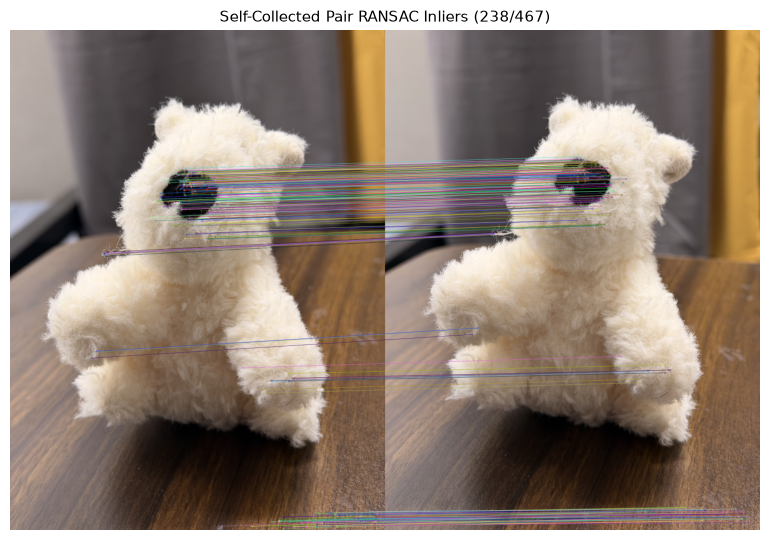

Stitched canvas size: 1654 x 2100 | Overlap pixels: 2845818


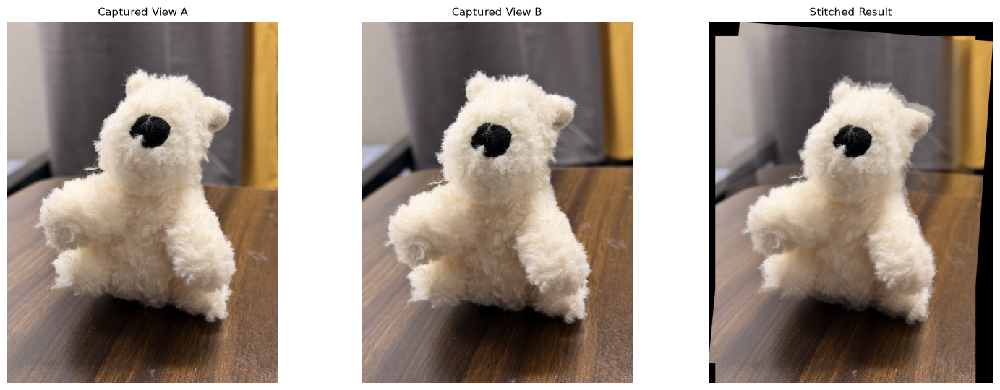

In [10]:
pair_a_full = read_color(own_photos[19])
pair_b_full = read_color(own_photos[20])

aa = cv2.resize(pair_a_full, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
bb = cv2.resize(pair_b_full, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
ga = cv2.cvtColor(aa, cv2.COLOR_BGR2GRAY)
gb = cv2.cvtColor(bb, cv2.COLOR_BGR2GRAY)

ka, da = sift.detectAndCompute(ga, None)
kb, db = sift.detectAndCompute(gb, None)
own_good = [m for m, n in bf.knnMatch(db, da, k=2) if m.distance < 0.72 * n.distance]

psrc = np.float32([kb[m.queryIdx].pt for m in own_good]).reshape(-1, 1, 2)
pdst = np.float32([ka[m.trainIdx].pt for m in own_good]).reshape(-1, 1, 2)
H_own, in_own = cv2.findHomography(psrc, pdst, cv2.RANSAC, 4.0)
in_own_cnt = int(in_own.sum())
own_proj = cv2.perspectiveTransform(psrc, H_own).reshape(-1, 2)
own_err = np.linalg.norm(own_proj - pdst.reshape(-1, 2), axis=1)

print(f'SIFT keypoints: pair A = {len(ka)}, pair B = {len(kb)}')
print(f'Ratio-filtered matches: {len(own_good)} | RANSAC inliers: {in_own_cnt}/{len(own_good)} ({in_own_cnt / len(own_good):.1%})')
print(f'Median inlier reprojection error: {float(np.median(own_err[in_own.ravel() != 0])):.3f} px')
print('Homography Matrix H_own (pair B -> pair A):\n', H_own)

own_match_vis = cv2.drawMatches(
    bb, kb, aa, ka, own_good, None,
    matchesMask=in_own.ravel().tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
)
own_match_vis = cv2.resize(own_match_vis, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
show_images([to_rgb(own_match_vis)], [f'Self-Collected Pair RANSAC Inliers ({in_own_cnt}/{len(own_good)})'], cols=1, scale=(10.0, 5.5))

own_pano, own_m1, own_m2, own_size = stitch_pair(aa, bb, H_own)
print(f'Stitched canvas size: {own_size[0]} x {own_size[1]} | Overlap pixels: {int(np.count_nonzero(own_m1 & own_m2))}')
show_images(
    [to_rgb(aa), to_rgb(bb), to_rgb(own_pano)],
    ['Captured View A', 'Captured View B', 'Stitched Result'],
    cols=3,
    scale=(5.0, 5.5),
)

**Discussion of Self-Collected Pair Stitching:**
- **High feature density and dominant plane lock:** Thanks to the fluffy fur texture and wood grain, SIFT + `BFMatcher` yields $467$ ratio-filtered matches between these two adjacent frames, and **RANSAC** finds **$238$ consistent inliers** ($51.0\%$, median error $1.72\text{ px}$) concentrated mainly across the plush puppy's front torso and face.
- **2D Planar Homography vs. 3D Parallax:** Because we intentionally translated the smartphone sideways at close range (~$25\text{ to }35\text{ cm}$) to build **stereo baseline** for COLMAP rather than rotating around the camera's optical center, points at different depths (the protruding nose/paws vs. the wooden tabletop vs. the room background) move by different pixel amounts (**motion parallax**). Fitting a single $3 \times 3$ **planar homography** $H_{\text{own}}$ aligns the main front plane of the puppy nicely, while slight perspective stretching/ghosting appears along depth transitions at the desk edge and background. This contrast directly demonstrates why **planar homography** is ideal for distant scenes (Part I Q2), whereas close-range 3D objects require full **multi-view 3D geometry reconstruction** (Part II.1).